# Indego Bikes: Do electric bikes tempt riders to go faster?

**Group members:** Student A, Student B, Student C, Student D

*(This is an example project. Replace these placeholders with your group members' names.)*

<center><b>Abstract</b></center>

Bike-share programs are increasingly popular worldwide. Following successful programs in Amsterdam, Paris, and Copenhagen, the City of Philadelphia launched Indego Bikes in 2015. Indego maintains a fleet of over 2,000 bicycles, more than half of which are electric bicycles. Urban cycling can be dangerous. To investigate whether riders travel faster on electric bicycles, we compared the duration of trips made using standard and electric bicycles between a pair of stations two miles apart in downtown Philadelphia. Following a pre-specified plan, we used 161 trips from the third quarter of 2023 (113 electric, 48 standard), excluding trips longer than twice Google's 13-minute estimate. Electric-bike trips averaged 0.75 minutes shorter (12.23 versus 12.98). A one-sided permutation test that shuffles bike-type labels gives p = 0.069, so we cannot reject the null hypothesis at the 5% significance level; a 95% bootstrap confidence interval for the difference (−0.03 to 1.53 minutes) likewise includes zero. The result is suggestive but not significant. Even if real, the effect size is small (about 45 seconds on a two-mile ride) and likely of limited practical importance; these results do not support the conclusion that riders of electric bicycles are at greater risk solely due to speed.

![Shuffled differences in mean trip duration, with the observed difference marked](abstract_figure.png)

*Figure: Differences in mean trip duration (standard − electric) from 20,000 shuffles of the bike-type labels, which is what we would expect if bike type made no difference. The red dot marks the observed difference of 0.75 minutes. 6.9% of shuffles were at least that large (p = 0.069).*

### Team Roles
| Member | Role | Responsibilities |
|---|---|---|
| Student A | Project coordinator | Schedules meetings, keeps the project on track, leads the presentation |
| Student B | Data wrangling | Loads and cleans the trip and station data; selects the trips for the test |
| Student C | Statistical analysis | Writes the analysis plan; runs the permutation test, bootstrap confidence interval and sensitivity check |
| Student D | Background research and writing | Finds and summarizes references; drafts the abstract, conclusions and limitations |

Everyone makes the visualizations for their own part and reviews the whole notebook before submission.

![Indego riders](Indego_riders.jpg)
You are probably all familiar with [Indego Bikes](https://www.rideindego.com/), the Philly bike-share program. What you may not know is that Indego makes ridership data available on their [trip data](https://www.rideindego.com/about/data/) website. 

In this sample project, we will:
* Explore trip data for the third quarter of 2023
* Make data visualizations
* Formulate a hypothesis
* Test the hypothesis using simulation

In [1]:
import numpy as np
from datascience import *
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')
%matplotlib inline

## Load the data

In [2]:
# Note: this is a large data set, hence the low_memory flag.
indego = Table.read_table('indego-trips-2023-q3-2.csv', low_memory=False)

## Exploratory Data Analysis

In [3]:
indego.show(3)

trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,bike_id,plan_duration,trip_route_category,passholder_type,bike_type
677293140,2,7/1/2023 0:00,7/1/2023 0:02,3271,39.9476,-75.2295,3246,39.9478,-75.223,25775,30,One Way,Indego30,electric
677304406,27,7/1/2023 0:00,7/1/2023 0:27,3060,39.9592,-75.1704,3255,39.951,-75.1644,14583,30,One Way,Indego30,standard
677304584,32,7/1/2023 0:00,7/1/2023 0:32,3057,39.9644,-75.1799,3165,39.9582,-75.1782,5191,1,One Way,Day Pass,standard


In [4]:
indego.num_rows

353256

**That is a lot of bike trips!**

### Trip Duration
The data set includes the trip durations, which are measured in minutes according to the [website](https://www.rideindego.com/about/data/). Let's see how this variable is distributed. 

In [5]:
min_duration = min(indego.column('duration'))
max_duration = max(indego.column('duration'))
print(f" The longest trip was {max_duration} minutes.")
print(f" The shortest trip was {min_duration} minutes.")

 The longest trip was 1440 minutes.
 The shortest trip was 1 minutes.


The Indego site says trips below 1 minute are removed. Probably, the rider changed their mind and put the bike back. **But honestly, can you go anywhere in one minute?  Let's see.**

There is a field "trip_route_category" that is either "Round Trip" or "One Way." If a 1-minute trip is round trip, clearly the bike never left the station. Are there any one-way trips?

In [6]:
quick_trips = indego.where('duration', 1).where('trip_route_category', 'One Way')
quick_trips.show(5)

trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,bike_id,plan_duration,trip_route_category,passholder_type,bike_type
677454652,1,7/1/2023 7:54,7/1/2023 7:55,3061,39.9543,-75.1776,3161,39.9549,-75.1809,14717,30,One Way,Indego30,standard
677507754,1,7/1/2023 9:48,7/1/2023 9:49,3124,39.9537,-75.1396,3169,39.9538,-75.1426,14598,30,One Way,Indego30,standard
677597704,1,7/1/2023 12:48,7/1/2023 12:49,3190,39.9489,-75.1699,3000,nan,nan,26260,365,One Way,Indego365,electric
677630041,1,7/1/2023 13:53,7/1/2023 13:54,3208,39.9505,-75.1932,3020,39.9486,-75.1901,22610,30,One Way,Indego30,electric
677719554,1,7/1/2023 14:29,7/1/2023 14:30,3330,39.9538,-75.1647,3000,nan,nan,22127,1,One Way,Day Pass,electric


**Wow!** Yes, there are some really fast trips! How is that possible? Let's look at the start and end stations for the first of these trips in the table above:

start_station is 3061

end_station is 3161

We need to know the station names. Fortunately, Indego provides this in a separate CSV file.

### Load Station Name Data

In [7]:
station_names = Table.read_table('indego-stations-2023-10-01.csv', low_memory=False)
station_names.show(3)

Station_ID,Station_Name,Day of Go_live_date,Status,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
3000,Virtual Station,4/23/2015,Active,nan,nan,nan,nan,nan,nan
3004,Municipal Services Building Plaza,4/23/2015,Inactive,nan,nan,nan,nan,nan,nan
3005,"Welcome Park, NPS",4/23/2015,Active,nan,nan,nan,nan,nan,nan


In [8]:
# We just need the first two columns
station_names = station_names.select('Station_ID', 'Station_Name')
print('Start Station')
print(station_names.where('Station_ID', 3061))
print()
print('End Station')
print(station_names.where('Station_ID', 3161))

Start Station
Station_ID | Station_Name
3061       | 23rd & Market

End Station
Station_ID | Station_Name
3161       | 30th Street Station East


![Quick bike trip](quick_trip.jpg)

If you put these addresses into Google Maps, it says this is a two-minute ride. I can imagine a Penn or Drexel student getting off the train at 30th Street Station and making this ride in double-quick time, as it is only a third of a mile. Alternatively, the clocks at the two stations might not be perfectly in sync. Or it could be a minute and 29 seconds rounded down. Anyway, it appears feasible.

Now let's look at the overall distribution of ride durations.

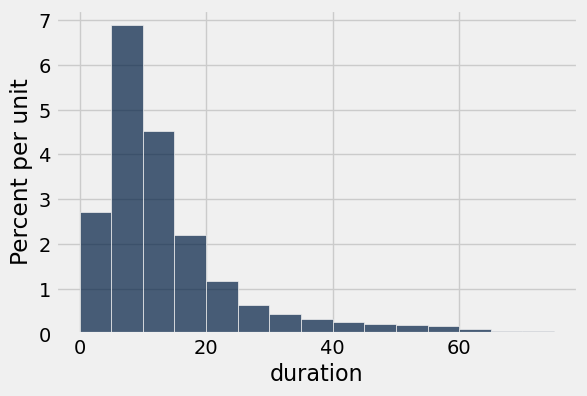

In [9]:
indego.hist('duration', bins=np.arange(0, 80, 5))

We see most trips are short, the peak being 5-10 minutes. Very few are over an hour.

### Trips by Time of Day

Let's look at the distribution of rides by time of day. This requires parsing the hour from strings such as the following.

In [10]:
st = indego.column("start_time")
example = st[100]
example

'7/1/2023 1:29'

To extract the hour, we can first split the date and time on the space.

In [11]:
example.split()

['7/1/2023', '1:29']

Then we keep the second term and split on the colon.
`example.split()[1].split(":")`

In [12]:
example.split()[1].split(":")

['1', '29']

Hour is the first element after this second split. Finally, we convert the hour from a string to an integer so we can plot the distribution.

In [13]:
hour = example.split()[1].split(":")[0]
hour = int(hour)
hour

1

Put this in a function.

In [14]:
def extract_hour(date_time_string):
    '''
    This function expects a datetime string in the form
    '7/1/2023 1:29' and returns just the hour.
    '''
    hour = date_time_string.split()[1].split(":")[0]
    return int(hour)

In [15]:
# Test our function
test_datetime = st[5000]
print(test_datetime)
print(extract_hour(test_datetime))

7/2/2023 16:57
16


Now use our function to add a "start_hour" column to our data table.

In [16]:
indego = indego.with_column('start_hour', indego.apply(extract_hour, 'start_time'))
indego.show(3)

trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,bike_id,plan_duration,trip_route_category,passholder_type,bike_type,start_hour
677293140,2,7/1/2023 0:00,7/1/2023 0:02,3271,39.9476,-75.2295,3246,39.9478,-75.223,25775,30,One Way,Indego30,electric,0
677304406,27,7/1/2023 0:00,7/1/2023 0:27,3060,39.9592,-75.1704,3255,39.951,-75.1644,14583,30,One Way,Indego30,standard,0
677304584,32,7/1/2023 0:00,7/1/2023 0:32,3057,39.9644,-75.1799,3165,39.9582,-75.1782,5191,1,One Way,Day Pass,standard,0


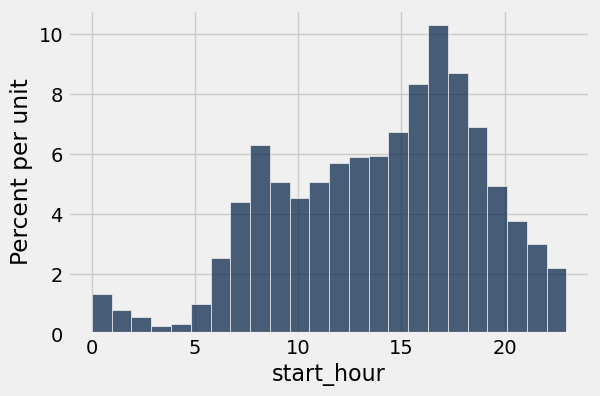

In [17]:
# Use 24 bins for the 24 hours in a day.
indego.hist('start_hour', bins=24)

So the least likely time to start an Indego ride is 3 AM (Hmmm, I wonder why :-), and peak ridership is in the late afternoon and evening with the maximum at about 6 PM (18:00 hours).

### Rides by Type of Bicycle
Indego offers two types of bikes: standard and electric. Let's see which constitutes the majority of the rides.

In [18]:
indego_grp = indego.group('bike_type')
indego_grp

bike_type,count
electric,191142
standard,162114


Wow! The ebikes, which Indego introduced only a few years earlier, account for slightly more than half of the rides.

This raises the question: are more riders choosing ebikes because they prefer them, or simply because there are more ebikes to ride? A first step is to find what fraction of the bike fleet is ebikes and how many rides each bike gets. We can count the bikes using the bike ID in concert with the bike type.

In [19]:
ebike = indego.where('bike_type', 'electric')
ebike_id = np.unique(ebike.column('bike_id'))
num_ebikes = len(ebike_id)

standard = indego.where('bike_type', 'standard')
standard_id = np.unique(standard.column('bike_id'))
num_standard = len(standard_id)

print("The number of ebikes is:", num_ebikes)
print("The number of standard bikes is:", num_standard)

The number of ebikes is: 1230
The number of standard bikes is: 918


So there are more ebikes in the fleet. Compare ratios.

In [20]:
rides_per_ebike = indego_grp.column('count').item(0) / num_ebikes
rides_per_ebike

155.4

In [21]:
rides_per_standard = indego_grp.column('count').item(1) / num_standard
rides_per_standard

176.59477124183007

So even though ebikes make up more of the fleet, each standard bike was ridden a bit more often this quarter: about 177 rides per standard bike versus 155 per ebike. This ratio measures **utilization**, not preference. Many things besides what riders want affect how often a bike gets used:

* **Availability:** whether that type of bike is docked at the station when a rider arrives.
* **Charge level:** riders may pass over an ebike with a low battery, and ebikes that need charging may be out of service.
* **Price:** ebikes cost extra to ride. Here is the current [pricing information](https://www.rideindego.com/buy-a-pass/#/).

To learn which type riders actually prefer, we would need to know which bikes were available, and how charged they were, when each rider made a choice.

## Background
Electric bikes make it easy to ride faster with less effort, and researchers have asked whether that extra speed makes them riskier. In a naturalistic study of a university bike-share fleet, Langford, Chen and Cherry (2015) tracked riders of conventional and electric bikes. The two groups behaved similarly in most safety-related ways, such as wrong-way riding and traffic-signal violations, but the e-bike riders traveled faster. Gogola (2018) asks directly whether e-bikes are more dangerous than traditional bicycles. Siman-Tov (2018) looked at hospital data from the Israel National Trauma Registry and found that people injured on e-bikes were more severely hurt, and more likely to have head injuries, than people injured on conventional bicycles.

If e-bikes lead riders to go faster, and faster crashes cause worse injuries, that could help explain these findings. Philadelphia's Indego system, where more than half of the fleet is electric, lets us check the first link in that chain with real trip data.

### References
* Langford, B. C., Chen, J., & Cherry, C. R. (2015). Risky riding: Naturalistic methods comparing safety behavior from conventional bicycle riders and electric bike riders. *Accident Analysis & Prevention*, 82, 220–226.
* Gogola, M. (2018, April). Are the e-bikes more dangerous than traditional bicycles? In *2018 XI International Science-Technical Conference Automotive Safety* (pp. 1–4). IEEE.
* Siman-Tov, M. (2018). A look at electric bike casualties: Do they differ from the mechanical bicycle? *Journal of Transport & Health*, 11, 176–182.

## Research Question
**Do Indego riders complete the same trip faster on electric bikes than on standard bikes?**

We use trip duration between the same two stations as our measure of speed: if riders go faster on ebikes, the same trip should take less time. This builds on Langford et al. (2015), who found that e-bike riders traveled faster in a university bike-share fleet. We ask whether the same pattern shows up in a large city bike-share system.

## Hypothesis
**Hypothesis: Riders bike at higher speeds on ebikes.**

**Null Hypothesis: Any difference in mean ride speed by type of bike can be explained by natural variability in ride times.**

To test this hypothesis, we can compare mean trip duration by bicycle type where all of the trips start and end at the same two bike stations. Presumably, the time taken to check out and return the bikes would be roughly the same, so any difference would be attributable to ride speed. Clearly, we need stations reasonably far apart so the ride isn't too short, and a pair of stations with a lot of trips to furnish an adequate sample size.

### Analysis Plan
We wrote down this plan before looking at any trip durations between our two stations. Settling these choices in advance keeps us from picking, even unintentionally, the version of the analysis that gives the result we hoped for.

**Station pair.** We compare trips in both directions between 15th & Spruce (station 3010) and Point Breeze & Tasker (station 3053). *Disclosure:* this pair was not chosen blind. In an earlier exploratory pass, we found it by taking the busiest starting station and its most popular destination among rides of 10–20 minutes, so that search did look at durations. A fully pre-specified analysis would choose the pair with a rule that never looks at durations, such as the busiest pair of stations at least a mile apart.

**Exclusion rule.** Google Maps says this route is 2.0 miles and takes about 13 minutes by bike (see the map below). A trip much longer than that probably included a stop along the way, so we drop any trip longer than 26 minutes, twice Google's estimate. The rule is the same for both bike types, and we keep every shorter trip.

**Test.** Our statistic is the mean trip duration on standard bikes minus the mean trip duration on electric bikes. Our hypothesis says this difference is positive, so the test is one-sided. We use a permutation test that shuffles the bike-type labels, and the p-value is the fraction of shuffled differences at least as large as the observed one. We will reject the null hypothesis if p < 0.05 (significance level α = 0.05). We will also report a 95% bootstrap confidence interval for the difference.

![bike_route from Google Maps](bike_route.jpg)

### Selecting the Trips
Following the plan, we take every trip between the two stations, in both directions.

In [22]:
station_names.where('Station_ID', are.contained_in(make_array(3010, 3053)))

Station_ID,Station_Name
3010,15th & Spruce
3053,Point Breeze & Tasker


In [23]:
common_trip = indego.where('start_station', 3010).where('end_station', 3053)
reverse_trip = indego.where('start_station', 3053).where('end_station', 3010)
trip = common_trip.append(reverse_trip)
trip.num_rows

167

Next we apply the exclusion rule from the plan: drop trips longer than twice Google's 13-minute estimate.

In [24]:
cutoff = 2 * 13
num_dropped = trip.where('duration', are.above(cutoff)).num_rows
trip = trip.where('duration', are.below_or_equal_to(cutoff))
print(f"Dropped {num_dropped} trips longer than {cutoff} minutes; {trip.num_rows} trips remain.")

Dropped 6 trips longer than 26 minutes; 161 trips remain.


### Check for Outliers
Make a box plot. (You can learn more about box plots [here](https://statisticsbyjim.com/graphs/box-plot/).)

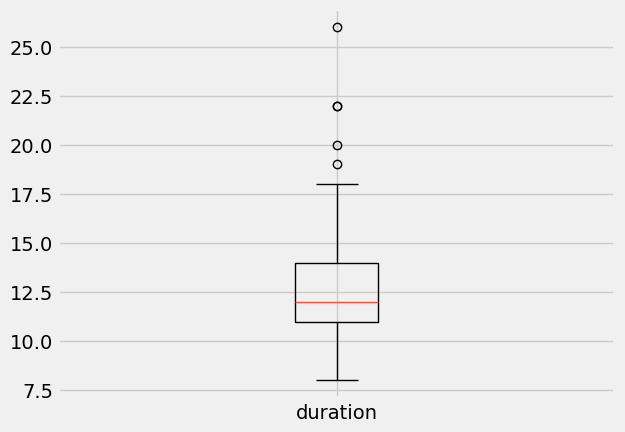

In [25]:
trip.select('duration').boxplot()

The box plot shows the trips that remain after the exclusion rule. A few rides are still well above the median, but our plan said to keep every trip of 26 minutes or less, so we keep them rather than deciding after the fact which points look too slow.

Notice that the median ride duration is 12 minutes, about a minute faster than Google predicts, but as any frequent bike rider will tell you, Google Maps tends to be conservative.

### Compare standard and ebike histograms

In [26]:
type_count = trip.group('bike_type')
type_count

bike_type,count
electric,113
standard,48


In [27]:
num_standard = trip.where('bike_type', 'standard').num_rows
num_ebike = trip.where('bike_type', 'electric').num_rows

In [28]:
print(f"Our total sample size is {num_standard + num_ebike} trips.")

Our total sample size is 161 trips.


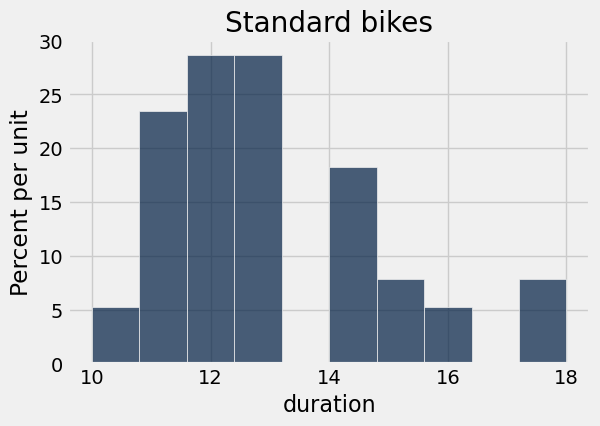

In [29]:
trip.where('bike_type', 'standard').hist('duration')
plt.title("Standard bikes");

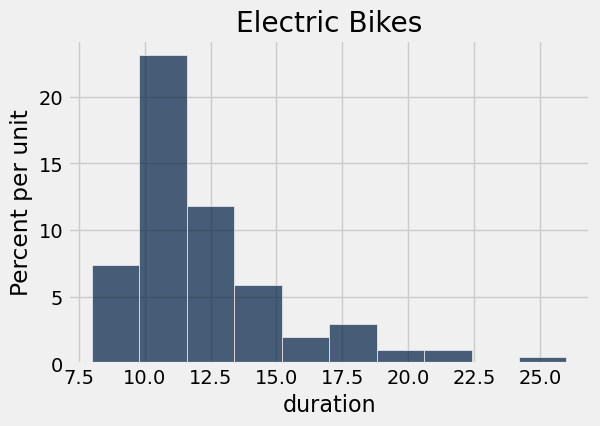

In [30]:
trip.where('bike_type', 'electric').hist('duration')
plt.title("Electric Bikes");

### A Note on Measurement
Indego records start and end times to the minute, so every trip duration is a whole number of minutes. The durations in our sample are:

In [31]:
np.unique(trip.column('duration'))

array([ 8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 22, 26])

A trip recorded as 12 minutes could really have taken anywhere from about 11 to 13 minutes. The effect we are looking for, a difference in means of about 0.75 minutes, is smaller than this one-minute resolution. Averaging over many trips helps, because the rounding errors tend to cancel out, which is why we can still estimate a difference in *means* to a fraction of a minute. But the coarse measurement adds noise to every trip, so it makes a small effect harder to detect.

It certainly appears the ebike riders are a bit quicker, but is the difference statistically significant?

As planned, our hypothesis is directional (riders are *faster* on ebikes), so our test statistic is the mean trip duration on standard bikes minus the mean trip duration on electric bikes. A positive value means trips on electric bikes were shorter.

In [32]:
standard_mean_duration = np.mean(trip.where('bike_type', 'standard').column('duration'))
ebike_mean_duration = np.mean(trip.where('bike_type', 'electric').column('duration'))
print(f"The average trip on a standard bike takes {np.round(standard_mean_duration, 2)} minutes.")
print(f"The average trip on an electric bike takes {np.round(ebike_mean_duration, 2)} minutes.")
print()
print(f"The difference in means is {np.round(standard_mean_duration - ebike_mean_duration, 2)} minutes")

The average trip on a standard bike takes 12.98 minutes.
The average trip on an electric bike takes 12.23 minutes.

The difference in means is 0.75 minutes


In [33]:
def standard_minus_electric(tbl):
    standard_mean = np.mean(tbl.where('bike_type', 'standard').column('duration'))
    electric_mean = np.mean(tbl.where('bike_type', 'electric').column('duration'))
    return standard_mean - electric_mean

observed_difference = standard_minus_electric(trip)
observed_difference

0.74907817109144403

So trips on electric bikes were shorter, but by less than a minute on average. Could this be due to chance? Run a simulation!

### Simulation Under the Null Hypothesis
If the null hypothesis is true, the type of bike has nothing to do with trip duration, so the "standard" and "electric" labels are interchangeable. We can simulate this by randomly shuffling the labels among the trips and recalculating the difference in means. This is the permutation test from [Inferential Thinking, Section 12.1](https://inferentialthinking.com/chapters/12/1/AB_Testing.html).

In [34]:
def one_shuffled_difference():
    shuffled_labels = trip.sample(with_replacement=False).column('bike_type')
    shuffled_table = trip.select('duration').with_column('bike_type', shuffled_labels)
    return standard_minus_electric(shuffled_table)

In [35]:
# Test function
one_shuffled_difference()

-0.73506637168141609

A single shuffle gives one simulated difference. We need to repeat the shuffle many times to see how the difference is distributed under the null hypothesis.

In [36]:
# Fix the random seed so the results, and the abstract figure, are the same every time.
# We chose this seed before running the simulation. Trying different seeds until
# p < 0.05 would be p-hacking.
np.random.seed(2023)

# Be patient! This can take a minute or so.
num_repetitions = 20000
differences = make_array()
for i in np.arange(num_repetitions):
    differences = np.append(differences, one_shuffled_difference())

In [37]:
results = Table().with_column('Simulated Difference', differences)

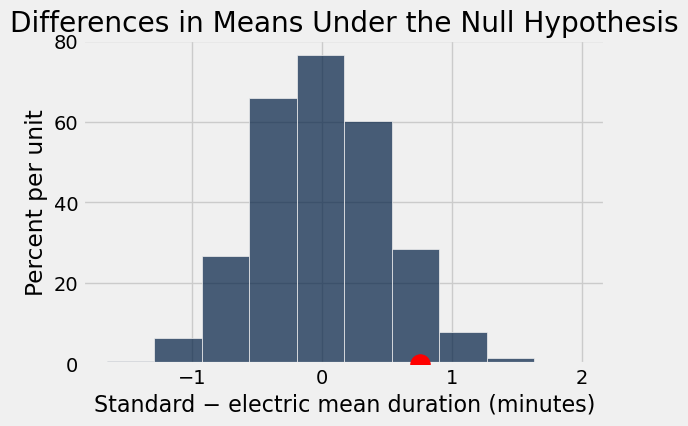

In [38]:
results.hist('Simulated Difference')
plt.scatter(observed_difference, 0, color='red', s=200, zorder=3)
plt.xlabel('Standard − electric mean duration (minutes)')
plt.title('Differences in Means Under the Null Hypothesis')
# Save this plot; the abstract at the top of the notebook displays it.
plt.savefig('abstract_figure.png', bbox_inches='tight', dpi=150);

In [39]:
# One-sided p-value: the fraction of simulated differences at least as large as the observed one
p_value = np.count_nonzero(differences >= observed_difference) / num_repetitions
p_value

0.06865

### Bootstrap Confidence Interval
The p-value tells us whether the observed difference could be due to chance. To show how uncertain our estimate of the difference is, we also build a 95% confidence interval for the difference in mean trip duration (standard − electric). We bootstrap: resample each group of trips with replacement, recalculate the difference in means, and repeat many times ([Inferential Thinking, Section 13.2](https://inferentialthinking.com/chapters/13/2/Bootstrap.html)).

In [40]:
standard_trips = trip.where('bike_type', 'standard')
electric_trips = trip.where('bike_type', 'electric')

def one_bootstrap_difference():
    standard_resample = standard_trips.sample()
    electric_resample = electric_trips.sample()
    return np.mean(standard_resample.column('duration')) - np.mean(electric_resample.column('duration'))

In [41]:
np.random.seed(2023)
boot_differences = make_array()
for i in np.arange(5000):
    boot_differences = np.append(boot_differences, one_bootstrap_difference())

In [42]:
left_end = percentile(2.5, boot_differences)
right_end = percentile(97.5, boot_differences)
print(f"95% confidence interval for standard − electric: ({np.round(left_end, 2)}, {np.round(right_end, 2)}) minutes")

95% confidence interval for standard − electric: (-0.03, 1.53) minutes


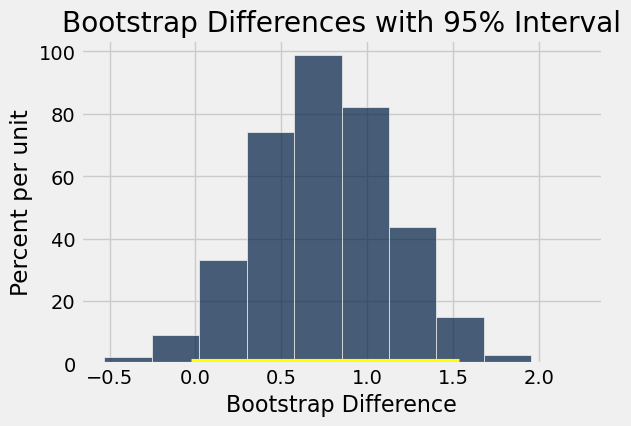

In [43]:
Table().with_column('Bootstrap Difference', boot_differences).hist('Bootstrap Difference')
plt.plot([left_end, right_end], [0, 0], color='yellow', lw=8);
plt.title('Bootstrap Differences with 95% Interval');

The interval runs from −0.03 to 1.53 minutes. Because it contains 0, it agrees with our hypothesis test: at the 5% level we cannot rule out that there is no difference. Most of the interval is above 0, though, which is consistent with trips on electric bikes being somewhat shorter, by anywhere from essentially nothing to about a minute and a half.

### Sensitivity Check: Difference in Medians (not in our plan)
Our plan named the difference in **means** as the test statistic. As a sensitivity check, we repeat the permutation test using the difference in **medians** instead. We report it for transparency only; it does not replace the planned test.

Why not just report whichever statistic gives the smaller p-value? Because choosing the statistic after seeing the data is a form of **p-hacking**. If we try several analyses and report the one that crosses 0.05, the chance of a false positive is much larger than 5%.

In [44]:
def standard_minus_electric_median(tbl):
    standard_median = np.median(tbl.where('bike_type', 'standard').column('duration'))
    electric_median = np.median(tbl.where('bike_type', 'electric').column('duration'))
    return standard_median - electric_median

observed_median_difference = standard_minus_electric_median(trip)
observed_median_difference

2.0

In [45]:
# Same label shuffle as before, but with medians. Be patient! This can take a minute or so.
np.random.seed(2023)
median_differences = make_array()
for i in np.arange(num_repetitions):
    shuffled_labels = trip.sample(with_replacement=False).column('bike_type')
    shuffled_table = trip.select('duration').with_column('bike_type', shuffled_labels)
    median_differences = np.append(median_differences, standard_minus_electric_median(shuffled_table))

median_p_value = np.count_nonzero(median_differences >= observed_median_difference) / num_repetitions
median_p_value

0.0131

The median trip took 13 minutes on a standard bike and 11 minutes on an electric bike, a difference of 2 minutes, and this test gives p = 0.013. Had we switched to medians after seeing the data, we could have reported a "significant" result. We don't, for two reasons:

* **It wasn't the plan.** The 5% false-positive rate applies to the test we chose in advance. Picking a different statistic because it gives a smaller p-value breaks that guarantee.
* **Medians are coarse here.** Because durations are whole minutes, the medians can only move in steps of whole (or half) minutes. Most shuffles give a median difference of exactly 0, so a 2-minute gap stands out more than it should. The mean uses every trip and is less affected by the rounding.

Our headline result is still the planned test: suggestive, but not significant.

## Conclusions

The distributions hinted that riders might be slightly quicker on electric bikes: electric trips were about 0.75 minutes (roughly 45 seconds) shorter on average. However, when we shuffled the bike-type labels, 6.9% of the simulated differences were at least as large as the one we observed (p = 0.069). This is above the significance level of α = 0.05 that we set in our plan, so we cannot reject the null hypothesis. The data are consistent with riders being slightly faster on electric bikes, at least for a two-mile ride in the city, but the evidence is not strong enough to rule out chance. The 95% bootstrap confidence interval for the difference, −0.03 to 1.53 minutes, tells the same story: it includes 0. In short, the result is suggestive, but not statistically significant.

Two cautions. First, a sensitivity check using the difference in medians gave p = 0.013, but that test was not in our plan, and switching to it after seeing the data would be p-hacking. Second, durations are recorded in whole minutes, which is coarser than the 45-second effect we are trying to detect.

Would more data settle the question? More trips would make our estimate more precise: the bootstrap confidence interval would get narrower. But a narrower interval could still include 0, so more data would not guarantee a statistically significant result. We could get more trips by analyzing more station pairs and by downloading more quarters of data from the Indego site. (An exercise left to the reader ;-)

The **effect size**, however, appears to be small. Does anyone care if we shave 45 seconds off of a two-mile commuter ride? Unlikely. Even results that are "statistically significant" do not always have practical importance. It does not appear the ebike riders are taking greater risks because they are not going that much faster.

## Limitations
* **Observational data and self-selection.** Riders chose which type of bike to take; we did not assign them. People who pick ebikes may differ from people who pick standard bikes: they may be in more of a hurry, less fit, or riding at different times of day. A difference in trip duration could come from who rides each type of bike rather than from the bike itself, so this study cannot show that ebikes *cause* faster riding.
* **One station pair, one quarter.** All 161 trips are between two stations in July–September 2023. Summer riding, this particular route, and the people who ride it may not represent other routes, seasons or years.
* **Whole-minute durations.** Durations are recorded to the minute. That is coarser than the 45-second effect we are looking for, and it adds noise to every trip.
* **Multiple analyses.** The station pair came from an exploratory search that looked at trip durations, and we ran more than one analysis: the planned test of means, a bootstrap confidence interval and a median sensitivity check. Each extra look at the data raises the chance of finding something that seems significant just by luck. We guarded against this by naming one primary test in advance and treating everything else as secondary.
* **Trip duration is not speed.** We never see the route or any stops. A trip could take longer because the rider stopped, took a longer route or had trouble docking, not because they rode more slowly.

## Future Work
Any good scientific study ends with a reflection on possibilities for further study. There are many ideas we could pursue:

* How does ridership change with the weather? We could download Philly weather data and compare ridership on warm, sunny days versus cold, rainy ones.
* How does ridership change with the academic calendar? Do students dominate the ridership near universities? 
* Which stations still show activity in the wee hours of the morning? Where are people riding at 3 AM?
* How has the balance between standard and ebikes changed over the last few years?
* Are there parts of the city that are under-served and could use more stations?

**Just a few of many ideas for follow-up research!**
